# Fundamentos de Deep Learning: Conceitos e Implementações em Python — Parte I

Este notebook acompanha a aula de 2 horas sobre fundamentos de Deep Learning, com exemplos didáticos aplicados à área da saúde.

## Objetivos

Ao final deste notebook, você deverá ser capaz de:

- representar dados clínicos em formato tabular;
- compreender o fluxo básico de uma rede neural;
- criar dados simulados de pacientes;
- treinar uma rede neural simples para classificação binária;
- avaliar o modelo com métricas adequadas;
- discutir limitações e cuidados no uso de Deep Learning em saúde.

> Observação: os dados usados aqui são **simulados** e têm finalidade exclusivamente educacional. Este modelo não deve ser usado para decisão clínica real.

## 1. Instalação das bibliotecas

Execute a célula abaixo apenas se estiver em um ambiente que ainda não possui as bibliotecas instaladas.

No Google Colab, geralmente `numpy`, `pandas`, `scikit-learn`, `matplotlib` e `tensorflow` já estão disponíveis.

In [ ]:
# Descomente a linha abaixo caso precise instalar as dependências.
# !pip install numpy pandas scikit-learn matplotlib tensorflow

## 2. Importação das bibliotecas

Usaremos:

- `numpy` para gerar dados numéricos;
- `pandas` para organizar os dados em tabela;
- `scikit-learn` para dividir, normalizar e avaliar os dados;
- `tensorflow.keras` para criar e treinar a rede neural;
- `matplotlib` para visualizar resultados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

## 3. Contexto do problema

Vamos simular uma base de pacientes com algumas variáveis clínicas simples.

O objetivo será treinar uma rede neural para classificar se um paciente possui:

- `0`: baixo risco;
- `1`: alto risco.

As variáveis usadas serão:

- idade;
- temperatura corporal;
- frequência cardíaca;
- saturação de oxigênio;
- contagem de leucócitos.

## 4. Geração de dados simulados

Nesta etapa, criaremos uma base fictícia de pacientes.

A variável-alvo `alto_risco` será criada a partir de uma regra simples:

- idade acima de 65 anos;
- temperatura acima de 38 ºC;
- frequência cardíaca acima de 100 bpm;
- saturação abaixo de 93%;
- leucócitos acima de 12.000.

Se o paciente apresentar pelo menos dois desses critérios, será marcado como alto risco.

In [2]:
n = 1000

idade = np.random.randint(18, 90, n)
temperatura = np.random.normal(36.8, 1.2, n)
freq_cardiaca = np.random.normal(80, 15, n)
saturacao = np.random.normal(96, 3, n)
leucocitos = np.random.normal(8000, 2500, n)

# Evitando valores biologicamente muito fora do esperado na simulação
saturacao = np.clip(saturacao, 75, 100)
leucocitos = np.clip(leucocitos, 2500, 25000)

risco = (
    (idade > 65).astype(int) +
    (temperatura > 38).astype(int) +
    (freq_cardiaca > 100).astype(int) +
    (saturacao < 93).astype(int) +
    (leucocitos > 12000).astype(int)
)

alto_risco = (risco >= 2).astype(int)

df = pd.DataFrame({
    "idade": idade,
    "temperatura": temperatura,
    "freq_cardiaca": freq_cardiaca,
    "saturacao": saturacao,
    "leucocitos": leucocitos,
    "alto_risco": alto_risco
})

df.head()

,idade,temperatura,freq_cardiaca,saturacao,leucocitos,alto_risco
0,69,36.491820,86.710390,95.960481,2500.000000,0
1,32,38.029144,61.791089,95.428415,5824.020916,0
2,89,34.852972,109.158153,90.725421,9078.634585,1
3,78,37.209186,55.656331,97.915353,10195.488659,0
4,38,36.830686,91.935547,96.516552,6949.716096,0


## 5. Análise exploratória inicial

Antes de treinar o modelo, é importante conhecer os dados.

In [3]:
df.describe()

,idade,temperatura,freq_cardiaca,saturacao,leucocitos,alto_risco
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,52.881000,36.874984,80.617632,95.809783,7987.766692,0.190000
std,20.958915,1.225024,14.946548,2.762857,2459.430185,0.392497
min,18.000000,32.778067,29.197794,85.981499,2500.000000,0.000000
25%,34.750000,36.060058,70.428467,93.797683,6349.205309,0.000000
50%,52.500000,36.864246,80.987073,95.879832,7984.744279,0.000000
75%,71.000000,37.712519,91.049224,98.045956,9704.065240,0.000000
max,89.000000,40.600846,132.438167,100.000000,16065.329147,1.000000


In [4]:
df["alto_risco"].value_counts(normalize=True).rename("proporcao")

,proporcao
alto_risco,
0,0.81
1,0.19


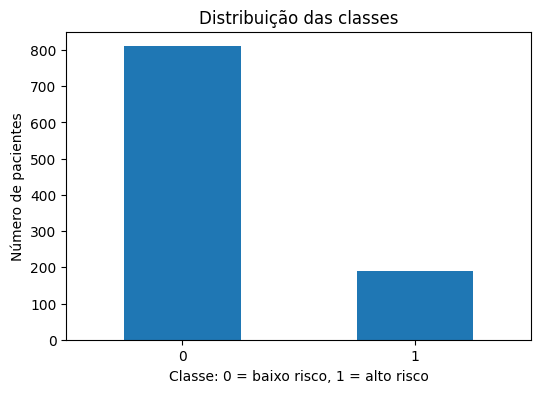

In [5]:
plt.figure(figsize=(6, 4))
df["alto_risco"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribuição das classes")
plt.xlabel("Classe: 0 = baixo risco, 1 = alto risco")
plt.ylabel("Número de pacientes")
plt.xticks(rotation=0)
plt.show()

## 6. Separação entre entradas e saída

As variáveis de entrada serão armazenadas em `X`.

A variável-alvo será armazenada em `y`.

In [6]:
X = df[[
    "idade",
    "temperatura",
    "freq_cardiaca",
    "saturacao",
    "leucocitos"
]]

y = df["alto_risco"]

X.head()

,idade,temperatura,freq_cardiaca,saturacao,leucocitos
0,69,36.491820,86.710390,95.960481,2500.000000
1,32,38.029144,61.791089,95.428415,5824.020916
2,89,34.852972,109.158153,90.725421,9078.634585
3,78,37.209186,55.656331,97.915353,10195.488659
4,38,36.830686,91.935547,96.516552,6949.716096


## 7. Divisão entre treino e teste

Dividiremos os dados em:

- 80% para treino;
- 20% para teste.

O parâmetro `stratify=y` preserva a proporção das classes nas duas partes.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Tamanho do conjunto de treino:", X_train.shape)
print("Tamanho do conjunto de teste:", X_test.shape)

Tamanho do conjunto de treino: (800, 5)
Tamanho do conjunto de teste: (200, 5)


## 8. Normalização dos dados

Redes neurais costumam treinar melhor quando as variáveis estão em escalas próximas.

Por exemplo:

- idade varia aproximadamente de 18 a 90;
- leucócitos podem variar de milhares a dezenas de milhares;
- saturação varia entre 75 e 100.

A normalização evita que uma variável domine o treinamento apenas por ter escala maior.

In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(X_train_scaled, columns=X.columns).head()

,idade,temperatura,freq_cardiaca,saturacao,leucocitos
0,-0.522011,-0.642547,0.524282,-1.138005,1.029587
1,-0.760809,-0.728996,-0.815338,1.508339,0.680911
2,1.245090,2.193909,-0.722692,0.295499,-1.290042
3,-0.617530,-0.418705,-1.694868,-0.960148,0.552541
4,0.719736,0.793460,-1.259570,-0.608210,-0.134633


## 9. Primeiro modelo: rede neural feedforward simples

Criaremos uma rede com:

- camada de entrada com 5 variáveis;
- primeira camada oculta com 16 neurônios e ativação ReLU;
- segunda camada oculta com 8 neurônios e ativação ReLU;
- camada de saída com 1 neurônio e ativação sigmoid.

A saída sigmoid representa uma probabilidade entre 0 e 1.

In [9]:
model = Sequential([
    Dense(16, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 0 (0.00 B)

## 10. Compilação do modelo

Para classificação binária, usaremos:

- `binary_crossentropy` como função de perda;
- `adam` como otimizador;
- `accuracy` como métrica inicial.

A acurácia é útil, mas na saúde devemos observar também precision, recall e F1-score.

In [10]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

## 11. Treinamento do modelo

Durante o treinamento, o modelo ajusta seus pesos para reduzir a função de perda.

Usaremos 30 épocas e uma parte do conjunto de treino será separada automaticamente para validação.

In [13]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.8875 - loss: 0.2739 - val_accuracy: 0.8375 - val_loss: 0.3822
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.8891 - loss: 0.2716 - val_accuracy: 0.8313 - val_loss: 0.3803
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8891 - loss: 0.2694 - val_accuracy: 0.8375 - val_loss: 0.3783
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8922 - loss: 0.2672 - val_accuracy: 0.8375 - val_loss: 0.3770
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8922 - loss: 0.2651 - val_accuracy: 0.8375 - val_loss: 0.3753
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8922 - loss: 0.2630 - val_accuracy: 0.8375 - val_loss: 0.3734
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.8938 - loss: 0.2610 - val_accuracy: 0.8375 - val_loss: 0.3717
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8938 - loss: 0.2589 - val_accuracy: 0.

## 12. Visualização da evolução do treinamento

Vamos observar a perda e a acurácia ao longo das épocas.

Sinais de alerta:

- perda de treino cai, mas perda de validação sobe;
- acurácia de treino aumenta muito, mas validação não acompanha.

Isso pode indicar overfitting.

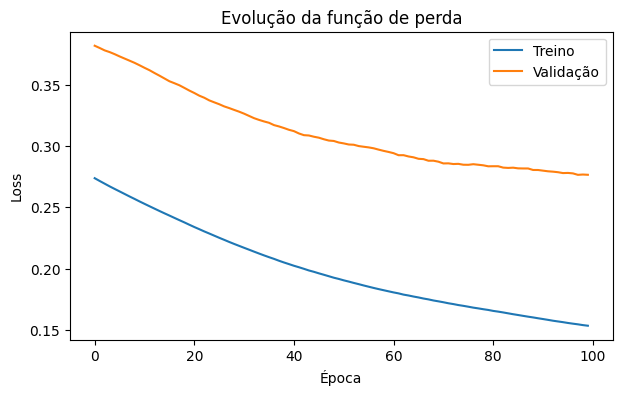

In [14]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Treino")
plt.plot(history.history["val_loss"], label="Validação")
plt.title("Evolução da função de perda")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.show()

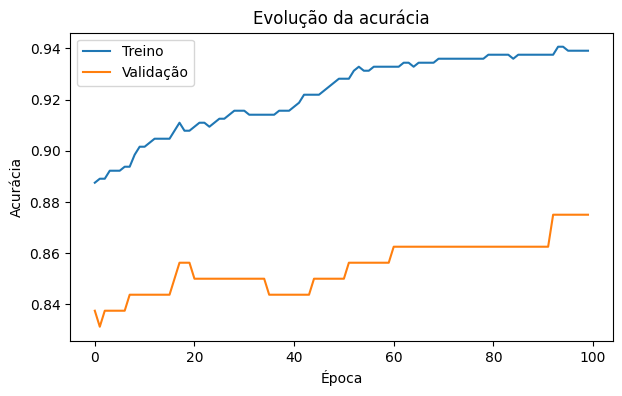

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Treino")
plt.plot(history.history["val_accuracy"], label="Validação")
plt.title("Evolução da acurácia")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()
plt.show()

## 13. Avaliação no conjunto de teste

Agora avaliaremos o modelo em dados que ele não viu durante o treinamento.

In [16]:
loss, accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)

print(f"Loss no teste: {loss:.4f}")
print(f"Acurácia no teste: {accuracy:.4f}")

Loss no teste: 0.3473
Acurácia no teste: 0.8550


## 14. Previsões

A rede retorna probabilidades.

Para transformar em classe, usaremos um limiar de 0,5:

- probabilidade menor que 0,5 → baixo risco;
- probabilidade maior ou igual a 0,5 → alto risco.

In [17]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

resultados = X_test.copy()
resultados["risco_real"] = y_test.values
resultados["probabilidade_alto_risco"] = y_pred_prob.ravel()
resultados["classe_prevista"] = y_pred

resultados.head(10)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


,idade,temperatura,freq_cardiaca,saturacao,leucocitos,risco_real,probabilidade_alto_risco,classe_prevista
853,32,35.773603,83.336512,95.014551,7655.840424,0,0.000100,0
939,19,38.705653,74.722637,98.649138,8671.546776,0,0.001723,0
479,34,37.975293,91.595200,92.719690,3832.109157,0,0.277440,0
420,19,35.920779,78.363372,97.962317,6021.538785,0,0.000003,0
687,65,35.230342,77.478598,96.502553,6090.528250,0,0.000480,0
485,26,38.636879,82.769792,96.330777,6419.848105,0,0.008239,0
277,77,38.185501,54.313408,100.000000,6342.553050,1,0.046698,0
284,71,37.882190,63.465795,93.775820,10912.809350,0,0.309804,0
198,18,36.988834,65.927339,96.393570,7076.172884,0,0.000025,0
296,50,36.875003,98.138992,96.967401,6505.599168,0,0.006834,0


## 15. Matriz de confusão

A matriz de confusão ajuda a entender os tipos de erro:

- verdadeiro negativo: baixo risco previsto corretamente;
- falso positivo: paciente baixo risco previsto como alto risco;
- falso negativo: paciente alto risco previsto como baixo risco;
- verdadeiro positivo: alto risco previsto corretamente.

Em triagem clínica, falsos negativos podem ser particularmente preocupantes.

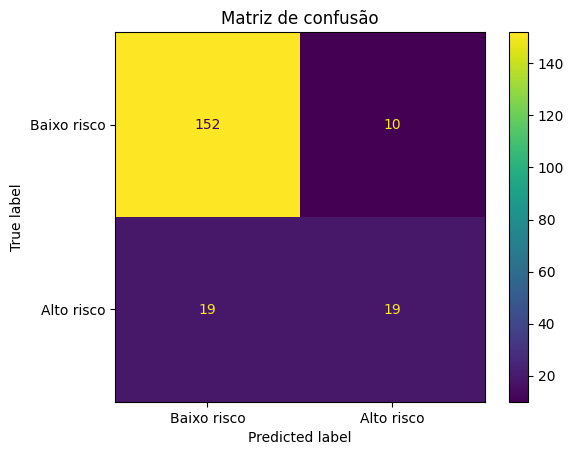

In [18]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Baixo risco", "Alto risco"]
)

disp.plot(values_format="d")
plt.title("Matriz de confusão")
plt.show()

## 16. Métricas de classificação

Vamos calcular:

- acurácia;
- precision;
- recall;
- F1-score.

Na saúde, a métrica mais importante depende do problema.

Em triagem, muitas vezes queremos alto recall para reduzir falsos negativos.

In [19]:
print("Acurácia:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

Acurácia: 0.855
Precision: 0.6551724137931034
Recall: 0.5
F1-score: 0.5671641791044776


In [20]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Baixo risco", "Alto risco"],
    zero_division=0
))

              precision    recall  f1-score   support

 Baixo risco       0.89      0.94      0.91       162
  Alto risco       0.66      0.50      0.57        38

    accuracy                           0.85       200
   macro avg       0.77      0.72      0.74       200
weighted avg       0.84      0.85      0.85       200



## 17. Testando um novo paciente

Vamos criar um paciente hipotético e pedir ao modelo para estimar o risco.

In [19]:
novo_paciente = pd.DataFrame({
    "idade": [72],
    "temperatura": [38.7],
    "freq_cardiaca": [112],
    "saturacao": [91],
    "leucocitos": [13500]
})

novo_paciente_scaled = scaler.transform(novo_paciente)
prob = model.predict(novo_paciente_scaled)[0][0]
classe = int(prob >= 0.5)

print(f"Probabilidade estimada de alto risco: {prob:.2%}")
print("Classe prevista:", "Alto risco" if classe == 1 else "Baixo risco")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
Probabilidade estimada de alto risco: 93.94%
Classe prevista: Alto risco


## 18. Comparação com um modelo menor

Vamos testar uma rede mais simples:

- uma camada oculta com 8 neurônios;
- uma camada de saída.

O objetivo é comparar desempenho e refletir sobre complexidade.

In [20]:
model_small = Sequential([
    Dense(8, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dense(1, activation="sigmoid")
])

model_small.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_small = model_small.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

y_pred_prob_small = model_small.predict(X_test_scaled)
y_pred_small = (y_pred_prob_small >= 0.5).astype(int).ravel()

print(classification_report(
    y_test,
    y_pred_small,
    target_names=["Baixo risco", "Alto risco"],
    zero_division=0
))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
              precision    recall  f1-score   support

 Baixo risco       0.86      0.96      0.90       162
  Alto risco       0.63      0.32      0.42        38

    accuracy                           0.83       200
   macro avg       0.74      0.64      0.66       200
weighted avg       0.81      0.83      0.81       200



## 19. Comparação resumida entre modelos

In [21]:
comparacao = pd.DataFrame({
    "modelo": ["Rede 16-8", "Rede 8"],
    "acuracia": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_small)
    ],
    "precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_small, zero_division=0)
    ],
    "recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred_small, zero_division=0)
    ],
    "f1": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred_small, zero_division=0)
    ]
})

comparacao

,modelo,acuracia,precision,recall,f1
0,Rede 16-8,0.835,0.580645,0.473684,0.521739
1,Rede 8,0.835,0.631579,0.315789,0.421053


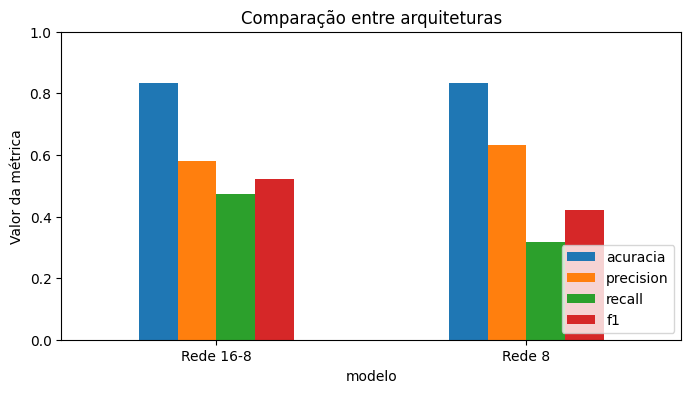

In [22]:
comparacao.set_index("modelo")[["acuracia", "precision", "recall", "f1"]].plot(kind="bar", figsize=(8, 4))
plt.title("Comparação entre arquiteturas")
plt.ylabel("Valor da métrica")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## 20. Uso de Early Stopping

O `EarlyStopping` interrompe o treinamento quando o desempenho na validação para de melhorar.

Isso pode ajudar a reduzir overfitting e economizar tempo de treinamento.

In [23]:
model_es = Sequential([
    Dense(32, activation="relu", input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model_es.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_es = model_es.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=0
)

print("Número de épocas executadas:", len(history_es.history["loss"]))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Número de épocas executadas: 77


In [24]:
y_pred_prob_es = model_es.predict(X_test_scaled)
y_pred_es = (y_pred_prob_es >= 0.5).astype(int).ravel()

print(classification_report(
    y_test,
    y_pred_es,
    target_names=["Baixo risco", "Alto risco"],
    zero_division=0
))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
              precision    recall  f1-score   support

 Baixo risco       0.90      0.95      0.92       162
  Alto risco       0.72      0.55      0.63        38

    accuracy                           0.88       200
   macro avg       0.81      0.75      0.78       200
weighted avg       0.87      0.88      0.87       200



## 21. Ajuste do limiar de decisão

O limiar padrão é 0,5, mas nem sempre esse é o melhor valor.

Em triagem clínica, pode ser desejável reduzir o limiar para aumentar o recall, identificando mais pacientes potencialmente graves.

Isso geralmente aumenta falsos positivos.

In [25]:
limiares = [0.3, 0.4, 0.5, 0.6, 0.7]
metricas_limiar = []

for limiar in limiares:
    pred_limiar = (y_pred_prob.ravel() >= limiar).astype(int)
    metricas_limiar.append({
        "limiar": limiar,
        "precision": precision_score(y_test, pred_limiar, zero_division=0),
        "recall": recall_score(y_test, pred_limiar, zero_division=0),
        "f1": f1_score(y_test, pred_limiar, zero_division=0)
    })

metricas_limiar = pd.DataFrame(metricas_limiar)
metricas_limiar

,limiar,precision,recall,f1
0,0.3,0.509804,0.684211,0.584270
1,0.4,0.525000,0.552632,0.538462
2,0.5,0.580645,0.473684,0.521739
3,0.6,0.631579,0.315789,0.421053
4,0.7,0.800000,0.210526,0.333333


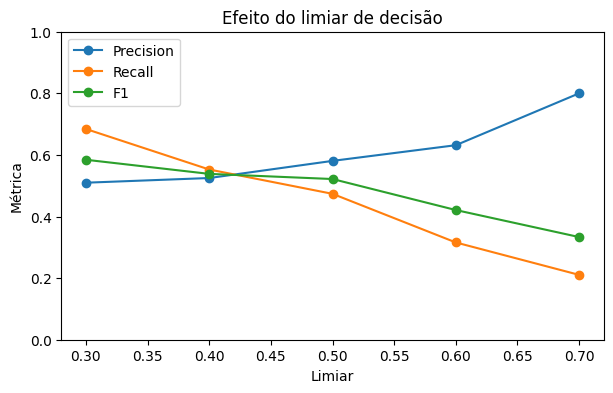

In [26]:
plt.figure(figsize=(7, 4))
plt.plot(metricas_limiar["limiar"], metricas_limiar["precision"], marker="o", label="Precision")
plt.plot(metricas_limiar["limiar"], metricas_limiar["recall"], marker="o", label="Recall")
plt.plot(metricas_limiar["limiar"], metricas_limiar["f1"], marker="o", label="F1")
plt.title("Efeito do limiar de decisão")
plt.xlabel("Limiar")
plt.ylabel("Métrica")
plt.ylim(0, 1)
plt.legend()
plt.show()

## 22. Discussão: cuidados no uso em saúde

Este exemplo mostra o fluxo técnico básico, mas aplicações reais exigem muitos cuidados.

Pontos importantes:

- dados simulados não representam a complexidade clínica real;
- dados reais podem conter ausências, erros e vieses;
- a população de um hospital pode ser diferente da população de outro;
- acurácia isolada pode mascarar problemas importantes;
- falsos negativos e falsos positivos têm impactos diferentes;
- modelos devem ser validados com especialistas;
- decisões clínicas não devem ser automatizadas sem governança, validação e segurança.

## 23. Exercícios

1. Altere o número de neurônios da primeira rede e observe o impacto nas métricas.
2. Adicione uma nova camada oculta e compare os resultados.
3. Modifique o número de épocas para 10, 50 e 100.
4. Teste diferentes limiares de decisão.
5. Explique por que o recall pode ser importante em sistemas de triagem.
6. Discuta o que seria necessário para usar dados clínicos reais em um projeto semelhante.

## 24. Síntese da aula

Nesta aula, vimos que:

- Deep Learning usa redes neurais com múltiplas camadas;
- um neurônio artificial realiza uma soma ponderada seguida de uma ativação;
- redes feedforward passam a informação da entrada até a saída;
- o treinamento ajusta pesos para reduzir o erro;
- métricas como precision, recall e F1-score são essenciais em saúde;
- modelos de IA em saúde exigem rigor técnico, ético e clínico.

> Ideia central: modelos de Deep Learning podem apoiar a análise de dados em saúde, mas devem ser avaliados com cuidado antes de qualquer uso real.